In [1]:
import os, sys
import ROOT as rt
## user define
sys.path.append(".")
sys.path.append("./Utils")
from SystHelper import *
from rpy2.robjects.packages import importr
from rpy2.robjects import FloatVector

INPUTDIR = sys.argv[1]
ERA = sys.argv[2]
REGION = sys.argv[3]

# # for dev
# INPUT_DIR = "/eos/user/h/hkwon/SWAN_projects/Zpeak/Outputs/DNN/"
# ERA = "ee18"
# REGION = "SR"

Welcome to JupyROOT 6.28/00


In [2]:
def get_str_lumi_channel(era):
    if("mm" in era):
        str_channel="#mu#mu"          
    if("ee" in era):
        str_channel="ee"               
    if("em" in era):
        str_channel="e#mu"
    if "16" in era:
        str_lumi="37.33"
    if "16pre" in era:
        str_lumi="19.52" 
    if "16post" in era:
        str_lumi="16.81"                 
    if "17" in era:
        str_lumi="41.48"
    if "18" in era:
        str_lumi="59.83"
    return str_channel, str_lumi

In [3]:
out_dir = "Outputs/Syst/"+ERA+"/"+REGION

os.system("mkdir -p "+out_dir+"/AN")
os.system("mkdir -p "+out_dir+"/root_files")

def draw_sys_ratio(f, process, sys, mass):
    c=rt.TCanvas()
    c.SetGrid()
    c.SetRightMargin(0.3)
    rt.gStyle.SetPalette(rt.kRainBow)
    rt.gStyle.SetOptStat(0)
    l = rt.TLegend(0.75,0.42,0.9,0.87)
    l.SetBorderSize(0)
    h_nom = f.Get("signal_region/"+process)
    n_h_nom = h_nom.Integral()
    list_hist=[] # kind of hack..(?) hist object seems to remain to the end
    list_hist_clone=[]
    for s in sys:
        h = f.Get("signal_region/"+process+"_"+s)
        list_hist.append(h)
        h_new = h.Clone("")
        list_hist_clone.append(h_new)
        h_new.SetTitle("")
        h_new.GetYaxis().SetTitle("Sys/Nom")
        h_new.GetXaxis().SetTitle("DNN score")
        h_new.SetLineWidth(3)
        h_new.SetFillColor(0)
        n_h_new = h_new.Integral()
        eff = n_h_new/n_h_nom
        h_new.Divide(h_nom)
        l.AddEntry(h_new, s+" (avg. "+str(round((eff-1),2)*100)+"%)", "l")
        l.SetTextSize(0.02)
        h_new.GetYaxis().SetRangeUser(0.8, 1.2)
        h_new.Draw("plc same hist")
    l.Draw()
    latex=rt.TLatex()
    latex.DrawLatexNDC( 0.13,0.85, "#scale[0.8]{#font[42]{"+p+"}}")    
    c.Draw()
    c.SaveAs("Syst/systeff_"+process+s+mass+"ttpdf.pdf")
    return c

In [36]:
import math
def draw_sys_ratio_bysource(ERA, f, processes, s, mass, smoothed = False):
    
    str_channel, str_lumi = get_str_lumi_channel(ERA)
    c=rt.TCanvas("", "", 800, 800)
    c.SetGrid()
    c.SetLeftMargin(0.12)
#     c.SetRightMargin(0.3)
    rt.gStyle.SetPalette(rt.kRainBow)
    rt.gStyle.SetOptStat(0)
    l = rt.TLegend(0.7,0.7,0.89,0.89)
    l.SetBorderSize(0)

    list_hist=[] # kind of hack..(?) hist object seems to remain to the end
    list_hist_clone=[]
    dic_smooth={}
    for i, process in enumerate(processes):
        h_nom = f.Get("signal_region/"+process)    
        h_u = f.Get("signal_region/"+process+"_"+s+"Up")
        h_d = f.Get("signal_region/"+process+"_"+s+"Down")
        list_hist.append(h_u)
        list_hist.append(h_d)
        h_u_new = h_u.Clone("")
        h_d_new = h_d.Clone("")
        list_hist_clone.append(h_u_new)
        list_hist_clone.append(h_d_new)              
        h_u_new.SetTitle("")
        h_u_new.GetYaxis().SetTitle("Sys/Nom")
        h_u_new.GetXaxis().SetTitle("DNN score")
        h_u_new.SetLineWidth(2)
        h_d_new.SetLineWidth(2)
        h_u_new.SetLineStyle(1)
        h_d_new.SetLineStyle(2)    
        h_u_new.SetLineColor(i+1)
        h_d_new.SetLineColor(i+1) 
        h_u_new.Divide(h_nom)
        h_d_new.Divide(h_nom)
#         if not "met" in s:
        l.AddEntry(h_u_new, process+" "+s+" Up", "l")
#         l.AddEntry(h_d_new, process+" "+s+" Down", "l")
        h_u_new.GetYaxis().SetRangeUser(0.8, 1.3)
        h_u_new.Draw("same hist")
#         h_d_new.Draw("same hist")
        if "met" in s and smoothed==True:
            h_smoothed_u = f.Get("signal_region/"+process+"_"+s+"_smoothedUp")
            list_hist.append(h_smoothed_u)
            h_smoothed_u_new = h_smoothed_u.Clone("")
            list_hist_clone.append(h_smoothed_u_new)
            h_smoothed_u_new.Divide(h_nom)
            h_smoothed_u_new.SetLineWidth(2)    
            h_smoothed_u_new.SetLineStyle(3)    
            h_smoothed_u_new.SetLineColor(i+1)
            h_smoothed_u_new.GetYaxis().SetRangeUser(0.8, 1.3)
            l.AddEntry(h_smoothed_u_new, process+" "+s+" smoothed Up", "l")
            h_smoothed_u_new.Draw("same hist")
            
        w, yup, ydown = [[] for _ in range(3)]
        # fill dictionary
        for nb in range(h_d_new.GetNbinsX()):
            w.append(h_nom.GetBinContent(nb+1))  
            yup.append(h_u_new.GetBinContent(nb+1)) 
            ydown.append(h_d_new.GetBinContent(nb+1))  
        
        dic_smooth[process+s+"Nom"] = w
        dic_smooth[process+s+"Up"] = yup
        dic_smooth[process+s+"Down"] = ydown
                
    l.Draw()
    latex=rt.TLatex()
    latex.DrawLatexNDC(0.71, 0.92, "#font[42]{#scale[0.8]{"+str_lumi+" fb^{-1}(13 TeV)}}");
    latex.DrawLatexNDC(0.13, 0.92, "#font[62]{CMS}#font[42]{#it{#scale[0.8]{ Preliminary}}}");
    latex.DrawLatexNDC(0.15,0.85, "#scale[0.8]{#font[42]{"+str_channel+" channel}}") 
    
#     latex.DrawLatexNDC( 0.13,0.85, "#scale[0.8]{#font[42]{}}")    
    c.Draw()
    if smoothed==True:
        c.SaveAs(out_dir+"/AN/"+s+"_syst_by_source.pdf")
    else:
        c.SaveAs(out_dir+"/"+s+"_syst_by_source.pdf")
    return c, dic_smooth

In [5]:
masses = ["Zp-2500_CH-345"]

# Draw by source

In [6]:
# for swan
limma = importr("limma", lib_loc="~/Rpackages")
# for ci
# limma = importr("limma", lib_loc="/usr/lib64/R/library")


In [7]:
def write_sys_hist(out_file, h1):
    f = rt.TFile(out_file, "UPDATE") 
    f.cd("signal_region")
#     h1.Write("zp_"+sys+"Up", rt.TObject.kWriteDelete)
#     h2.Write("zp_"+sys+"Down", rt.TObject.kWriteDelete)
    h1.Write()
#     h2.Write()  

['l1prefiring', 'pu', 'll_eff', 'met', 'trig_eff', 'toppt', 'scale', 'metue', 'btagSF', 'hdamp', 'UE']
{'ttbarl1prefiringNom': [1133.4817536883056, 529.0172043386847, 268.434384861961, 165.12941624969244, 109.69040787220001, 66.19870829768479, 44.0665720757097, 34.54069669358432, 28.536249976605177, 25.193580294027925, 22.496034145355225, 23.087773475795984, 22.743121352046728, 20.185273023322225, 20.026242246851325, 23.865601992234588, 27.622989295050502, 28.69011763855815, 26.03819005563855, 12.495424032211304], 'ttbarl1prefiringUp': [1.0000562068112688, 1.0000542625777944, 1.000056158045536, 1.0000501674839521, 1.0000476946440418, 1.0000529556409565, 1.0000603791247202, 1.0000462908134722, 1.0000626231270127, 1.0000535164151978, 1.000054188848891, 1.0000489866442888, 1.0000436299550557, 1.0000453793647788, 1.000038313791949, 1.0000596945346485, 1.0000515237396195, 1.0000559415811674, 1.000053767372823, 1.0000673492934224], 'ttbarl1prefiringDown': [0.9999041618838921, 0.9999053864921

{'ttbartrig_effNom': [1133.4817536883056, 529.0172043386847, 268.434384861961, 165.12941624969244, 109.69040787220001, 66.19870829768479, 44.0665720757097, 34.54069669358432, 28.536249976605177, 25.193580294027925, 22.496034145355225, 23.087773475795984, 22.743121352046728, 20.185273023322225, 20.026242246851325, 23.865601992234588, 27.622989295050502, 28.69011763855815, 26.03819005563855, 12.495424032211304], 'ttbartrig_effUp': [1.0038667428055075, 1.0032928574791289, 1.0029752725489491, 1.0028156678548394, 1.0027527890225407, 1.0026561161687924, 1.0025881993742225, 1.0026068067213882, 1.0025159181545251, 1.002579900773581, 1.0025436529536855, 1.0024605969393425, 1.002524296750373, 1.0025585996900948, 1.0024857423384117, 1.0025513890742122, 1.0024210678854242, 1.0025473993492726, 1.0024707238138617, 1.0021477315337435], 'ttbartrig_effDown': [0.9957624880873849, 0.9963941709456142, 0.9967394879174563, 0.9969146453395762, 0.9969762207194793, 0.9970766517827225, 0.9971455220381324, 0.997

{'ttbarmetueNom': [1133.4817536883056, 529.0172043386847, 268.434384861961, 165.12941624969244, 109.69040787220001, 66.19870829768479, 44.0665720757097, 34.54069669358432, 28.536249976605177, 25.193580294027925, 22.496034145355225, 23.087773475795984, 22.743121352046728, 20.185273023322225, 20.026242246851325, 23.865601992234588, 27.622989295050502, 28.69011763855815, 26.03819005563855, 12.495424032211304], 'ttbarmetueUp': [1.002981434375118, 0.9908701573161374, 0.9981789067429524, 0.9869146142634209, 0.9910617808317311, 1.0169565871619581, 1.003869106010414, 0.9741385379211643, 1.0138501987354012, 0.9969896256971137, 1.013994566645851, 1.0232611622214196, 0.9519204071311369, 0.9700421856530241, 1.0367590645890201, 0.9702025737421721, 1.0098003987423596, 1.0099145472536453, 1.0014482985427389, 0.9882646870329518], 'ttbarmetueDown': [1.0098639533298996, 1.0143733294614274, 1.0125640883262592, 1.0279588269999154, 1.012732689933146, 1.0202763188407746, 1.028845940101718, 0.978619721431899

Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/l1prefiring_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/pu_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/ll_eff_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/met_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/trig_eff_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/toppt_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/scale_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/metue_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/btagSF_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/hdamp_syst_by_source.pdf has been created
Info in <TCanv

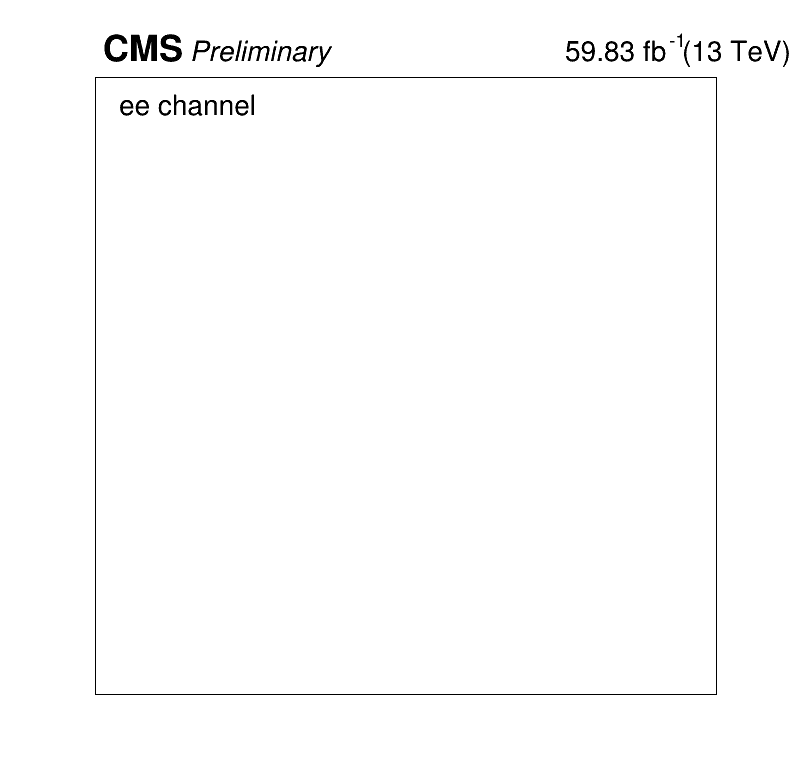

In [16]:
x = FloatVector([0.025, 0.075, 0.125, 0.175, 0.225, 0.275, 0.325, 0.375, 0.425, 0.475, 0.525, 0.575, 0.625, 0.675, 0.725, 0.775, 0.825, 0.875, 0.925, 0.975])

for mass in masses:
#     in_file = INPUT_DIR+ERA+"/"+REGION+"/root_files/shape_v1_20230430wp80_ANv3"+mass+"_v1.root"
    in_file = INPUT_DIR+"/"+REGION+"/root_files/shape_v1_20230430wp80_ANv3"+mass+"_v1.root"
    out_file = out_dir+"/root_files/"+"shape_v1_20230430wp80_ANv3"+mass+"_smoothed_v1.root"
    os.system("cp "+in_file+" "+out_file)

    f = rt.TFile(in_file)

    rt.gDirectory.cd("signal_region")

    processes = ["ttbar", "ww", "zp"]
#     list_sys = get_sys_list()
#     list_sys.remove("scale")
    list_sys = ["l1prefiring", "pu", "ll_eff", "met", "trig_eff", "toppt", "scale", "metue", "btagSF", "hdamp", "UE"]
    print(list_sys)
    for sys in list_sys:
        c, dic_smooth = draw_sys_ratio_bysource(ERA, f, processes, sys, mass)
        if "met" in sys:
            for process in processes:
                yup = FloatVector(dic_smooth[process+sys+'Up'])
                n = dic_smooth[process+sys+'Nom']
                w = np.sqrt(n)
                w = FloatVector(w)
                l = limma.weightedLowess(x, yup, w, span=0.4, output_style="lowess")
                smoothed_up = np.array(l[0])
                nbin = 20
                h_Up = rt.TH1D(process+"_"+sys+"_smoothedUp", process+"_"+sys+"_smoothedUp", nbin, 0, 1)           
                for nb in range(nbin):
                    h_Up.SetBinContent(nb+1, n[nb]*smoothed_up[nb])
                write_sys_hist(out_file, h_Up)

Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/AN/l1prefiring_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/AN/pu_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/AN/ll_eff_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/AN/met_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/AN/trig_eff_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/AN/toppt_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/AN/scale_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/AN/metue_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/AN/btagSF_syst_by_source.pdf has been created
Info in <TCanvas::Print>: pdf file Outputs/Syst/ee18/SR/AN/hdamp_syst_by_source.pdf h

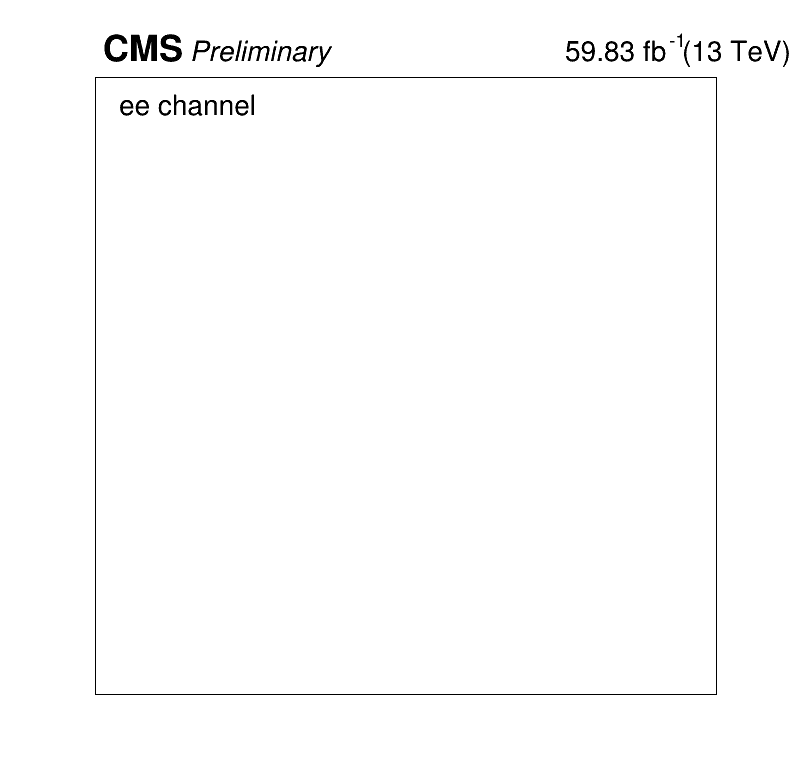

In [37]:
for mass in masses:
    out_file = out_dir+"/root_files/"+"shape_v1_20230430wp80_ANv3"+mass+"_smoothed_v1.root"

    f = rt.TFile(out_file)

    rt.gDirectory.cd("signal_region")

    processes = ["ttbar", "ww", "zp"]
#     processes = ["ttbar"]
    list_sys = ["l1prefiring", "pu", "ll_eff", "met", "trig_eff", "toppt", "scale", "metue", "btagSF", "hdamp", "UE"]
    for sys in list_sys:
        c, dic_smooth = draw_sys_ratio_bysource(ERA, f, processes, sys, mass, True)


 # Draw by process

In [ ]:
# !pip install rpy2 --user